In [4]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [5]:
GROUP = "C1"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C1_10,27,"[DATA/TRAINING/C1/C1_10/IMG_6497.HEIC, DATA/TR..."
1,C1_11,26,"[DATA/TRAINING/C1/C1_11/IMG_6665.HEIC, DATA/TR..."
2,C1_12,27,"[DATA/TRAINING/C1/C1_12/IMG_6797.HEIC, DATA/TR..."
3,C1_13,27,"[DATA/TRAINING/C1/C1_13/IMG_6929.HEIC, DATA/TR..."
4,C1_14,26,"[DATA/TRAINING/C1/C1_14/IMG_7188.HEIC, DATA/TR..."
5,C1_15,28,"[DATA/TRAINING/C1/C1_15/IMG_7316.HEIC, DATA/TR..."
6,C1_16,27,"[DATA/TRAINING/C1/C1_16/IMG_7446.HEIC, DATA/TR..."


In [6]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [7]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [8]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_6497.HEIC')

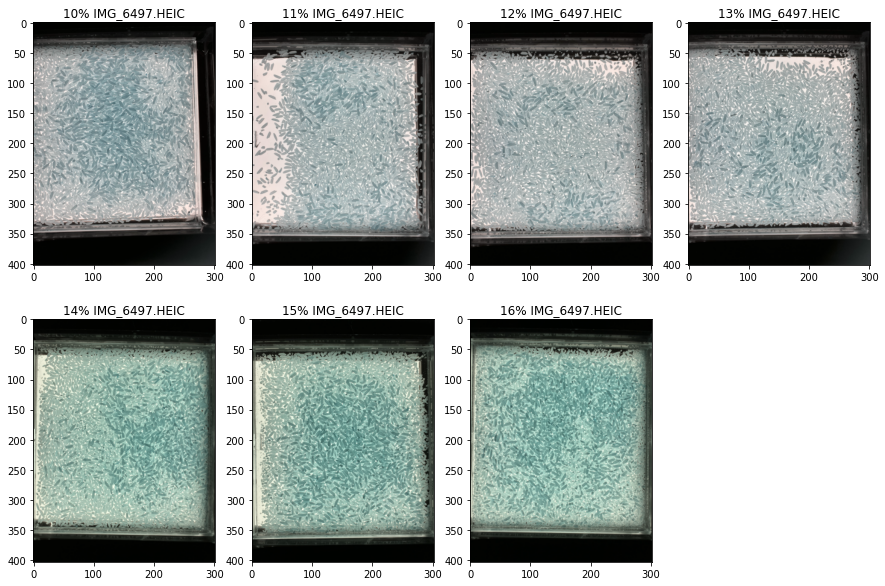

In [9]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [159]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [160]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.002558,183.695502,0.981845,5059.067677,0.353215,243.385356,20052.575204,8.261517,11.675378,0.000482,...,0.000342,4.401044,-0.337763,0.996407,25,1008,756,3,IMG_6497.HEIC,10
1,0.002292,146.979684,0.985582,5096.947306,0.369052,243.012642,20240.809539,8.299240,11.605632,0.000521,...,0.000371,4.288674,-0.353183,0.997204,25,1008,756,3,IMG_6498.HEIC,10
2,0.002293,151.625468,0.986083,5447.340873,0.366702,240.463991,21637.738026,8.275347,11.589999,0.000514,...,0.000359,4.338310,-0.346879,0.996880,25,1008,756,3,IMG_6499.HEIC,10
3,0.002166,146.740387,0.986416,5401.231503,0.366963,241.103600,21458.185625,8.300316,11.597060,0.000516,...,0.000370,4.287168,-0.354892,0.997267,25,1008,756,3,IMG_6500.HEIC,10
4,0.002209,152.729997,0.985864,5402.147946,0.365340,240.166839,21455.861786,8.271396,11.585686,0.000511,...,0.000370,4.300682,-0.351540,0.997073,25,1008,756,3,IMG_6501.HEIC,10
5,0.002403,162.952222,0.983861,5048.552137,0.352941,244.142772,20031.256326,8.317812,11.730374,0.000487,...,0.000341,4.394865,-0.338529,0.996559,25,1008,756,3,IMG_6502.HEIC,10
6,0.002783,148.562074,0.986470,5490.141318,0.364204,239.675012,21812.003198,8.186529,11.495321,0.000510,...,0.000355,4.338304,-0.339263,0.996290,25,1008,756,3,IMG_6503.HEIC,10
7,0.002605,164.568941,0.984891,5446.156741,0.351660,240.880473,21620.058021,8.207816,11.606278,0.000479,...,0.000371,4.278821,-0.347102,0.996732,25,1008,756,3,IMG_6504.HEIC,10
8,0.002713,163.264112,0.984950,5424.156513,0.358463,240.216343,21533.361941,8.262818,11.638615,0.000490,...,0.000341,4.402453,-0.337245,0.996368,25,1008,756,3,IMG_6505.HEIC,10
9,0.002883,162.526388,0.984963,5404.109249,0.359351,239.674535,21453.910610,8.256512,11.631432,0.000486,...,0.000338,4.404127,-0.337140,0.996349,25,1008,756,3,IMG_6506.HEIC,10


# Classification

In [161]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [162]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [163]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [164]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [165]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [166]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.880952,0.833333,0.856481,HRLK,C1,RF_C,25,1008,756,3
1,2,0.894737,0.928571,0.880952,0.904135,HRLK,C1,RF_C,25,1008,756,3
2,3,0.894737,0.916667,0.904762,0.910675,HRLK,C1,RF_C,25,1008,756,3
3,4,0.842105,0.845238,0.833333,0.839243,HRLK,C1,RF_C,25,1008,756,3
4,5,0.894737,0.928571,0.880952,0.904135,HRLK,C1,RF_C,25,1008,756,3
5,6,0.894737,0.928571,0.904762,0.916512,HRLK,C1,RF_C,25,1008,756,3
6,7,0.947368,0.964286,0.928571,0.946092,HRLK,C1,RF_C,25,1008,756,3
7,8,0.736842,0.750000,0.761905,0.755906,HRLK,C1,RF_C,25,1008,756,3
8,9,0.944444,0.964286,0.928571,0.946092,HRLK,C1,RF_C,25,1008,756,3
9,10,0.833333,0.833333,0.857143,0.845070,HRLK,C1,RF_C,25,1008,756,3


In [167]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C1,RF_C,0.872515,0.871429,0.882434,0.894048


### MLP Classifier

In [168]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [169]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [170]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.894737,0.892857,0.880952,0.886865,HRLK,C1,MLP_C,25,1008,756,3
1,2,0.894737,0.916667,0.904762,0.910675,HRLK,C1,MLP_C,25,1008,756,3
2,3,0.894737,0.916667,0.904762,0.910675,HRLK,C1,MLP_C,25,1008,756,3
3,4,0.736842,0.819048,0.761905,0.789443,HRLK,C1,MLP_C,25,1008,756,3
4,5,0.842105,0.880952,0.809524,0.843729,HRLK,C1,MLP_C,25,1008,756,3
5,6,0.894737,0.916667,0.880952,0.898455,HRLK,C1,MLP_C,25,1008,756,3
6,7,0.947368,0.964286,0.952381,0.958296,HRLK,C1,MLP_C,25,1008,756,3
7,8,0.842105,0.892857,0.857143,0.874636,HRLK,C1,MLP_C,25,1008,756,3
8,9,0.944444,0.952381,0.928571,0.940325,HRLK,C1,MLP_C,25,1008,756,3
9,10,0.944444,0.952381,0.952381,0.952381,HRLK,C1,MLP_C,25,1008,756,3


In [171]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C1,MLP_C,0.883626,0.883333,0.896548,0.910476


### XGBoost Classifier

In [172]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [173]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.684211,0.726190,0.690476,0.707883,HRLK,C1,XGB_C,25,1008,756,3
1,2,0.842105,0.880952,0.833333,0.856481,HRLK,C1,XGB_C,25,1008,756,3
2,3,0.736842,0.690476,0.761905,0.724434,HRLK,C1,XGB_C,25,1008,756,3
3,4,0.894737,0.928571,0.857143,0.891429,HRLK,C1,XGB_C,25,1008,756,3
4,5,0.842105,0.845238,0.833333,0.839243,HRLK,C1,XGB_C,25,1008,756,3
5,6,0.947368,0.964286,0.952381,0.958296,HRLK,C1,XGB_C,25,1008,756,3
6,7,0.736842,0.738095,0.738095,0.738095,HRLK,C1,XGB_C,25,1008,756,3
7,8,0.894737,0.916667,0.904762,0.910675,HRLK,C1,XGB_C,25,1008,756,3
8,9,0.944444,0.952381,0.952381,0.952381,HRLK,C1,XGB_C,25,1008,756,3
9,10,0.888889,0.916667,0.880952,0.898455,HRLK,C1,XGB_C,25,1008,756,3


In [174]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C1,XGB_C,0.841228,0.840476,0.847737,0.855952


# External validation

In [175]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C1_10,5,"[DATA/TEST/C1/C1_10/IMG_6492.HEIC, DATA/TEST/C..."
1,C1_11,5,"[DATA/TEST/C1/C1_11/IMG_6655.HEIC, DATA/TEST/C..."
2,C1_12,5,"[DATA/TEST/C1/C1_12/IMG_6788.HEIC, DATA/TEST/C..."
3,C1_13,5,"[DATA/TEST/C1/C1_13/IMG_6917.HEIC, DATA/TEST/C..."
4,C1_14,5,"[DATA/TEST/C1/C1_14/IMG_7178.HEIC, DATA/TEST/C..."
5,C1_15,5,"[DATA/TEST/C1/C1_15/IMG_7304.HEIC, DATA/TEST/C..."
6,C1_16,5,"[DATA/TEST/C1/C1_16/IMG_7436.HEIC, DATA/TEST/C..."


In [176]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [177]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [178]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.002742,179.745676,0.983337,5393.415460,0.364484,242.146388,21393.916163,8.287667,11.649365,0.000499,...,0.000356,4.361321,-0.344974,0.996838,25,1008,756,3,IMG_6492.HEIC,10
1,0.002652,175.148492,0.983410,5278.874327,0.362911,240.044878,20940.348816,8.239187,11.595833,0.000501,...,0.000360,4.337936,-0.343795,0.996672,25,1008,756,3,IMG_6493.HEIC,10
2,0.002219,176.498188,0.984314,5626.118707,0.369348,242.689597,22327.976638,8.388387,11.712858,0.000516,...,0.000373,4.317633,-0.358054,0.997550,25,1008,756,3,IMG_6494.HEIC,10
3,0.002440,189.467257,0.982670,5466.595956,0.362882,239.198359,21676.916565,8.327631,11.706890,0.000498,...,0.000357,4.369136,-0.348520,0.997072,25,1008,756,3,IMG_6495.HEIC,10
4,0.002278,176.261267,0.983138,5226.574628,0.353714,242.256687,20730.037243,8.288304,11.685240,0.000490,...,0.000355,4.349414,-0.345248,0.996839,25,1008,756,3,IMG_6496.HEIC,10
0,0.005566,185.423110,0.984004,5796.084969,0.350125,259.786243,22998.916764,8.103255,11.508512,0.000463,...,0.000312,4.513810,-0.318326,0.994715,25,1008,756,3,IMG_6655.HEIC,11
1,0.005731,187.442782,0.983408,5648.699717,0.359804,259.517724,22407.356088,8.104197,11.473630,0.000479,...,0.000321,4.488915,-0.323121,0.995069,25,1008,756,3,IMG_6657.HEIC,11
2,0.004334,190.221799,0.983851,5889.639081,0.356416,254.141241,23368.334526,8.152735,11.535910,0.000482,...,0.000320,4.498971,-0.323880,0.995280,25,1008,756,3,IMG_6659.HEIC,11
3,0.005380,205.272496,0.982234,5777.068386,0.354356,256.874112,22903.001050,8.195260,11.626247,0.000467,...,0.000336,4.452048,-0.332992,0.995978,25,1008,756,3,IMG_6662.HEIC,11
4,0.005191,174.848396,0.985011,5832.519845,0.372511,261.571109,23155.230984,8.280028,11.613975,0.000507,...,0.000361,4.362984,-0.350935,0.997091,25,1008,756,3,IMG_6663.HEIC,11


In [179]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [180]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [181]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [182]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [183]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.75      0.60      0.67         5
     Class 3       0.57      0.80      0.67         5
     Class 4       1.00      0.60      0.75         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.86        35
   macro avg       0.88      0.86      0.86        35
weighted avg       0.88      0.86      0.86        35



## MLP

In [184]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [185]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       1.00      0.40      0.57         5
     Class 3       0.50      1.00      0.67         5
     Class 4       1.00      0.60      0.75         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.83        35
   macro avg       0.90      0.83      0.83        35
weighted avg       0.90      0.83      0.83        35



## XGBC

In [186]:
y_pred = modelXGBC.predict(X_test_scale) 

In [187]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.60      0.60      0.60         5
     Class 3       0.57      0.80      0.67         5
     Class 4       0.75      0.60      0.67         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.80        35
   macro avg       0.82      0.80      0.80        35
weighted avg       0.82      0.80      0.80        35

